<a href="https://colab.research.google.com/github/KakaPerpetuo/TP1-DeteccaoDeAnomaliasVisuais/blob/main/BCC406_MariaClara_LuizVictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP1 — BCC406
###Nomes: Maria Clara Silva Perpetuo e Luiz Victor da Silva Lima;
###Matrículas: 22.1.4010 e 22.2.4070;



In [1]:
# ---- 1. Ambiente e dados ---------------------------------------------------
# No Colab: adicione a pasta compartilhada "TP1" ao seu Drive como atalho
# (botão direito -> Organizar -> Adicionar atalho -> Meu Drive). Ela aparece
# em /content/drive/MyDrive/TP1; se você a colocou em outro lugar, ajuste
# PASTA_DRIVE. Copiar o .zip para o disco local da máquina e descompactar lá é
# MUITO mais rápido do que ler as imagens direto do Drive.
import os
import subprocess
import sys

EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PASTA_DRIVE = "/content/drive/MyDrive/TP1"   # <- atalho da pasta compartilhada
    RAIZ = "/content/dados"
    os.makedirs(RAIZ, exist_ok=True)
    for z in ["bcc406_tp1_visa.zip", "bcc406_tp1_mvtec_ad2.zip"]:
        origem = os.path.join(PASTA_DRIVE, z)
        if os.path.exists(origem) and not os.path.exists(os.path.join(RAIZ, z)):
            subprocess.run(["cp", origem, RAIZ], check=True)
            subprocess.run(["unzip", "-q", "-o", os.path.join(RAIZ, z), "-d", RAIZ], check=True)
else:
    RAIZ = os.environ.get("TP1_RAIZ", "dados")

sys.path.insert(0, RAIZ)          # tp1_utils.py fica na raiz do pacote
import tp1_utils as U

DATASETS = [d for d in ["visa", "mvtec_ad2"] if os.path.isdir(os.path.join(RAIZ, d))]
print("RAIZ =", RAIZ, "| datasets encontrados:", DATASETS)

Mounted at /content/drive
RAIZ = /content/dados | datasets encontrados: ['visa', 'mvtec_ad2']


814 normais de treino, 90 de validação, 200 de teste


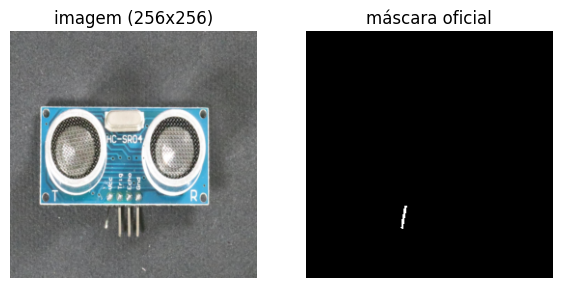

In [2]:
# ---- 2. Olhando os dados ---------------------------------------------------
import matplotlib.pyplot as plt

ds_exemplo = U.AnomalyDataset(RAIZ, "visa", "pcb1", split="test")
print(len(U.listar_amostras(RAIZ, "visa", "pcb1", "train")), "normais de treino,",
      len(U.listar_amostras(RAIZ, "visa", "pcb1", "val")), "de validação,",
      len(ds_exemplo), "de teste")
anomalas = [i for i, a in enumerate(ds_exemplo.amostras) if a.rotulo == 1]
item = ds_exemplo[anomalas[0]]
fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))
ax[0].imshow(U.desnormalizar(item["image"])); ax[0].set_title("imagem (256x256)")
ax[1].imshow(item["mask"][0], cmap="gray"); ax[1].set_title("máscara oficial")
for a in ax:
    a.axis("off")
plt.show()

In [3]:
# ---- 3. Baseline: ResNet-18 congelada + distância à média por posição -----
import numpy as np
import torch
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader

DEV = "cuda" if torch.cuda.is_available() else "cpu"
WORKERS = int(os.environ.get("TP1_WORKERS", 2))   # o Colab gratuito tem 2 CPUs
U.fixar_semente(42)


class ExtratorResNet18(torch.nn.Module):
    """Features de layer2 (28x28 -> 32x32 com entrada 256) + layer3 reamostrada."""

    def __init__(self):
        super().__init__()
        r = torchvision.models.resnet18(weights="IMAGENET1K_V1")
        self.base = torch.nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool, r.layer1)
        self.layer2, self.layer3 = r.layer2, r.layer3

    def forward(self, x):
        f2 = self.layer2(self.base(x))
        f3 = F.interpolate(self.layer3(f2), size=f2.shape[-2:], mode="bilinear",
                           align_corners=False)
        return F.avg_pool2d(torch.cat([f2, f3], 1), 3, 1, 1)   # (B, 384, 32, 32)


modelo = ExtratorResNet18().to(DEV).eval()
transform = U.transformacao_padrao(256)


@torch.no_grad()
def media_por_posicao(dataset, categoria):
    """Média das features normais de treino em cada posição: (384, 32, 32)."""
    ds = U.AnomalyDataset(RAIZ, dataset, categoria, split="train", transform=transform)
    soma, n = 0.0, 0
    for b in DataLoader(ds, batch_size=32, num_workers=WORKERS):
        f = modelo(b["image"].to(DEV))
        soma = soma + f.sum(dim=0)
        n += f.shape[0]
    return soma / n


@torch.no_grad()
def pontuar(dataset, categoria, mu):
    ds = U.AnomalyDataset(RAIZ, dataset, categoria, split="test", transform=transform)
    rot, esc, masc, mapas = [], [], [], []
    for b in DataLoader(ds, batch_size=32, num_workers=WORKERS):
        f = modelo(b["image"].to(DEV))
        m = ((f - mu[None]) ** 2).sum(1)                     # (B, 32, 32)
        mapas.append(U.mapa_para_eval(m.cpu()))              # (B, 256, 256)
        esc.append(m.flatten(1).amax(1).cpu().numpy())       # escore = máximo do mapa
        rot.append(b["label"].numpy())
        masc.append(b["mask"][:, 0].numpy().astype(np.uint8))
    return (np.concatenate(rot), np.concatenate(esc),
            np.concatenate(masc), np.concatenate(mapas))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 172MB/s]


Categoria       | Treino | Val  | Teste (N/A) | Tam. Médio Defeito (%)
-----------------------------------------------------------------
--- PCBs ---
pcb1            | 814    | 90   | 100  / 100  | 0.93%
pcb2            | 811    | 90   | 100  / 100  | 0.41%
pcb3            | 815    | 90   | 101  / 100  | 0.51%
pcb4            | 814    | 90   | 101  / 100  | 1.32%

--- Múltiplas instâncias ---
candle          | 810    | 90   | 100  / 100  | 0.27%
capsules        | 488    | 54   | 60   / 100  | 0.54%
macaroni1       | 810    | 90   | 100  / 100  | 0.07%
macaroni2       | 810    | 90   | 100  / 100  | 0.06%

--- Objetos únicos ---
cashew          | 405    | 45   | 50   / 100  | 1.69%
chewinggum      | 408    | 45   | 50   / 100  | 0.85%
fryum           | 405    | 45   | 50   / 100  | 3.46%
pipe_fryum      | 405    | 45   | 50   / 100  | 1.87%



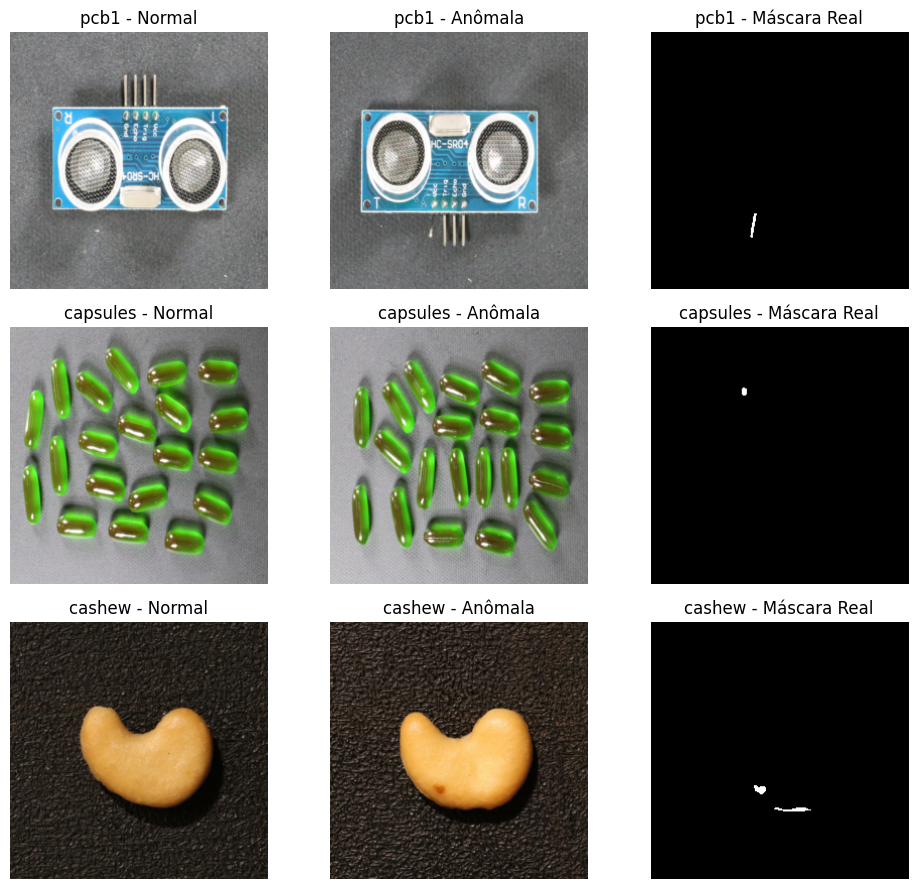

In [6]:
# 1. Agrupamento das categorias do VisA
grupos_visa = {
    "PCBs": ["pcb1", "pcb2", "pcb3", "pcb4"],
    "Múltiplas instâncias": ["candle", "capsules", "macaroni1", "macaroni2"],
    "Objetos únicos": ["cashew", "chewinggum", "fryum", "pipe_fryum"]
}

# 2 e 3. Contagem por split e medição do tamanho dos defeitos
print(f"{'Categoria':<15} | {'Treino':<6} | {'Val':<4} | {'Teste (N/A)':<11} | {'Tam. Médio Defeito (%)'}")
print("-" * 65)

transformacao = U.transformacao_padrao(256)

for grupo, categorias in grupos_visa.items():
    print(f"--- {grupo} ---")
    for cat in categorias:
        treino = U.listar_amostras(RAIZ, "visa", cat, "train")
        val = U.listar_amostras(RAIZ, "visa", cat, "val")
        teste = U.listar_amostras(RAIZ, "visa", cat, "test")

        teste_normais = sum(1 for a in teste if a.rotulo == 0)
        teste_anomalas = sum(1 for a in teste if a.rotulo == 1)

        # Carregando as máscaras para calcular a fração de pixels defeituosos
        ds_teste = U.AnomalyDataset(RAIZ, "visa", cat, split="test", transform=transformacao)
        fracoes_defeito = []

        for item in ds_teste:
            if item["label"] == 1:
                mascara = item["mask"][0].numpy()
                fracao = mascara.sum() / mascara.size
                fracoes_defeito.append(fracao * 100)

        media_tamanho = np.mean(fracoes_defeito) if fracoes_defeito else 0.0

        print(f"{cat:<15} | {len(treino):<6} | {len(val):<4} | {teste_normais:<4} / {teste_anomalas:<4} | {media_tamanho:.2f}%")
    print()

# 4. Plotagem de exemplos visuais (1 categoria por grupo para não poluir o notebook)
categorias_plot = ["pcb1", "capsules", "cashew"]
fig, axes = plt.subplots(len(categorias_plot), 3, figsize=(10, 3 * len(categorias_plot)))

for idx, cat in enumerate(categorias_plot):
    ds_teste = U.AnomalyDataset(RAIZ, "visa", cat, split="test", transform=transformacao)

    # Encontra o primeiro exemplo normal e o primeiro anômalo
    idx_normal = next(i for i, d in enumerate(ds_teste) if d["label"] == 0)
    idx_anom = next(i for i, d in enumerate(ds_teste) if d["label"] == 1)

    # Desnormaliza a imagem RGB para exibição correta com matplotlib
    img_normal = U.desnormalizar(ds_teste[idx_normal]["image"])
    img_anom = U.desnormalizar(ds_teste[idx_anom]["image"])
    mascara = ds_teste[idx_anom]["mask"][0].numpy()

    axes[idx, 0].imshow(img_normal)
    axes[idx, 0].set_title(f"{cat} - Normal")
    axes[idx, 0].axis("off")

    axes[idx, 1].imshow(img_anom)
    axes[idx, 1].set_title(f"{cat} - Anômala")
    axes[idx, 1].axis("off")

    axes[idx, 2].imshow(mascara, cmap="gray")
    axes[idx, 2].set_title(f"{cat} - Máscara Real")
    axes[idx, 2].axis("off")

plt.tight_layout()
plt.show()

In [7]:
import torch
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm # Para barra de progresso

# 1 e 3. Definir transformação (256x256 sem recorte para facilitar a avaliação)
transformacao = U.transformacao_padrao(tamanho=256, recorte=None)

# 2. Classe para pré-carregar as imagens redimensionadas na RAM (evita gargalo de I/O)
class CachedAnomalyDataset(Dataset):
    def __init__(self, raiz, dataset_name, categoria, split, transform):
        # Usa o dataset base do kit apenas para inicializar as rotinas
        self.base_ds = U.AnomalyDataset(raiz, dataset_name, categoria, split, transform)
        self.itens_cacheados = []

        print(f"Pré-carregando {len(self.base_ds)} imagens do split '{split}' na memória...")
        for i in tqdm(range(len(self.base_ds))):
            item = self.base_ds[i]
            # Salva o dicionário com os tensores já calculados e normalizados
            self.itens_cacheados.append({
                "image": item["image"], # Tensor (3, 256, 256)
                "label": item["label"],
                "mask": item["mask"],
                "path": item["path"],
                "defect": item["defect"]
            })

    def __len__(self):
        return len(self.itens_cacheados)

    def __getitem__(self, i):
        return self.itens_cacheados[i]

# Focando em uma categoria por vez para começar pequeno (como sugerido nas dicas)
categoria_alvo = "pcb1"

# Respeitando a R1: Apenas imagens normais no treino e validação
ds_treino = CachedAnomalyDataset(RAIZ, "visa", categoria_alvo, split="train", transform=transformacao)
ds_val = CachedAnomalyDataset(RAIZ, "visa", categoria_alvo, split="val", transform=transformacao)

# 4 e 5. Configurando os DataLoaders com num_workers=2
WORKERS = 2

# pin_memory=True acelera a transferência da RAM para a GPU
dl_treino = DataLoader(ds_treino, batch_size=32, shuffle=True, num_workers=WORKERS, pin_memory=True)
dl_val = DataLoader(ds_val, batch_size=32, shuffle=False, num_workers=WORKERS, pin_memory=True)

print(f"\nPipeline pronto! {len(dl_treino)} batches de treino e {len(dl_val)} batches de validação para {categoria_alvo}.")

Pré-carregando 814 imagens do split 'train' na memória...


100%|██████████| 814/814 [00:16<00:00, 50.21it/s]


Pré-carregando 90 imagens do split 'val' na memória...


100%|██████████| 90/90 [00:01<00:00, 53.87it/s]


Pipeline pronto! 26 batches de treino e 3 batches de validação para pcb1.


In [8]:
import torch
import torch.nn.functional as F
import torchvision
import numpy as np
from torch.utils.data import DataLoader

# 1. Configuração do Extrator de Features do Baseline (ResNet18 congelada)
class ExtratorResNet18(torch.nn.Module):
    def __init__(self):
        super().__init__()
        r = torchvision.models.resnet18(weights="IMAGENET1K_V1")
        self.base = torch.nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool, r.layer1)
        self.layer2, self.layer3 = r.layer2, r.layer3

    def forward(self, x):
        f2 = self.layer2(self.base(x))
        f3 = F.interpolate(self.layer3(f2), size=f2.shape[-2:], mode="bilinear", align_corners=False)
        return F.avg_pool2d(torch.cat([f2, f3], 1), 3, 1, 1)

DEV = "cuda" if torch.cuda.is_available() else "cpu"
modelo_baseline = ExtratorResNet18().to(DEV).eval()

@torch.no_grad()
def extrair_media_e_pontuar(dataset_name, categoria):
    # A. Treino: Calcular a média das features normais por posição espacial
    ds_treino = U.AnomalyDataset(RAIZ, dataset_name, categoria, split="train", transform=transformacao)
    dl_treino = DataLoader(ds_treino, batch_size=32, num_workers=WORKERS)

    soma, n = 0.0, 0
    for b in dl_treino:
        f = modelo_baseline(b["image"].to(DEV))
        soma += f.sum(dim=0)
        n += f.shape[0]
    mu = soma / n

    # B. Teste: Medir a distância quadrática de cada imagem para a média normal
    ds_teste = U.AnomalyDataset(RAIZ, dataset_name, categoria, split="test", transform=transformacao)
    dl_teste = DataLoader(ds_teste, batch_size=32, num_workers=WORKERS)

    rotulos, escores, mascaras, mapas_anomalia = [], [], [], []
    for b in dl_teste:
        f = modelo_baseline(b["image"].to(DEV))
        distancia = ((f - mu[None]) ** 2).sum(1) # Mapa em resolução menor (32x32)

        mapas_anomalia.append(U.mapa_para_eval(distancia.cpu())) # Converte para 256x256
        escores.append(distancia.flatten(1).amax(1).cpu().numpy()) # Escore da imagem = pixel máximo
        rotulos.append(b["label"].numpy())
        mascaras.append(b["mask"][:, 0].numpy().astype(np.uint8))

    # C. Avaliação oficial da categoria
    return U.avaliar_categoria(
        np.concatenate(rotulos),
        np.concatenate(escores),
        np.concatenate(mascaras),
        np.concatenate(mapas_anomalia)
    )

# 2. Loop principal sobre as 12 categorias do VisA
resultados_visa = {}
print(f"Rodando baseline nas 12 categorias do VisA...")
for cat in U.CATEGORIAS["visa"]:
    res = extrair_media_e_pontuar("visa", cat)
    resultados_visa[cat] = res
    print(f"{cat:12s} | AUROC-img: {res['img_auroc']:.1f}% | AUROC-px: {res['px_auroc']:.1f}% | AU-PRO: {res['au_pro']:.1f}%")

# 3. Salvar a tabela final para a comparação exigida nas regras
tabela_baseline = U.avaliar_dataset(resultados_visa, "visa")
U.salvar_submissao([tabela_baseline], "baseline-resnet18.csv")

Rodando baseline nas 12 categorias do VisA...
candle       | AUROC-img: 85.9% | AUROC-px: 97.3% | AU-PRO: 91.4%
capsules     | AUROC-img: 55.6% | AUROC-px: 85.5% | AU-PRO: 44.2%
cashew       | AUROC-img: 73.3% | AUROC-px: 98.2% | AU-PRO: 78.9%
chewinggum   | AUROC-img: 94.1% | AUROC-px: 98.2% | AU-PRO: 76.3%
fryum        | AUROC-img: 80.2% | AUROC-px: 96.4% | AU-PRO: 75.0%
macaroni1    | AUROC-img: 75.1% | AUROC-px: 93.7% | AU-PRO: 78.7%
macaroni2    | AUROC-img: 54.6% | AUROC-px: 93.2% | AU-PRO: 74.3%
pcb1         | AUROC-img: 83.9% | AUROC-px: 94.2% | AU-PRO: 60.0%
pcb2         | AUROC-img: 76.2% | AUROC-px: 95.9% | AU-PRO: 73.5%
pcb3         | AUROC-img: 68.2% | AUROC-px: 97.3% | AU-PRO: 72.4%
pcb4         | AUROC-img: 93.2% | AUROC-px: 96.4% | AU-PRO: 78.3%
pipe_fryum   | AUROC-img: 87.1% | AUROC-px: 99.3% | AU-PRO: 88.0%
dataset categoria  img_auroc  px_auroc  au_pro
   visa     MEDIA      77.29     95.48   74.24


'baseline-resnet18.csv'

In [9]:
import torch
import torch.nn as nn
import torchvision.models as models

# 1. Definindo a Professora (Congelada com pesos ImageNet)
class RedeProfessora(nn.Module):
    def __init__(self):
        super().__init__()
        # Backbone permitido: CNN com pesos ImageNet
        resnet = models.resnet18(weights="IMAGENET1K_V1")
        self.layer1 = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool, resnet.layer1)
        self.layer2 = resnet.layer2
        self.layer3 = resnet.layer3

        # Congelando todos os parâmetros da professora (training-free feature extractor)
        for param in self.parameters():
            param.requires_grad = False

    def forward(self, x):
        f1 = self.layer1(x)
        f2 = self.layer2(f1)
        f3 = self.layer3(f2)
        return f1, f2, f3

# 2. Definindo a Aluna (Treinada do zero via retropropagação)
class RedeAluna(nn.Module):
    def __init__(self):
        super().__init__()
        # Mesma arquitetura CNN, mas inicialização aleatória (weights=None)
        resnet = models.resnet18(weights=None)
        self.layer1 = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool, resnet.layer1)
        self.layer2 = resnet.layer2
        self.layer3 = resnet.layer3

    def forward(self, x):
        f1 = self.layer1(x)
        f2 = self.layer2(f1)
        f3 = self.layer3(f2)
        return f1, f2, f3

# 3. Instanciando as redes e enviando para a GPU
DEV = "cuda" if torch.cuda.is_available() else "cpu"

professora = RedeProfessora().to(DEV).eval()
aluna = RedeAluna().to(DEV)

print("Rede Professora (congelada) e Rede Aluna (destravada) configuradas com sucesso.")
print("Verificação de segurança: 0 backbones de atenção detectados. Setup em conformidade com as regras.")

Rede Professora (congelada) e Rede Aluna (destravada) configuradas com sucesso.
Verificação de segurança: 0 backbones de atenção detectados. Setup em conformidade com as regras.


Iniciando o treino em pcb1 por 30 épocas...
Época [01/30] | Treino: 1.7298 | Val: 1.2861 [SALVO]
Época [05/30] | Treino: 0.3777 | Val: 0.4168 [SALVO]
Época [10/30] | Treino: 0.2293 | Val: 0.3074 [SALVO]
Época [15/30] | Treino: 0.1931 | Val: 0.3036
Época [20/30] | Treino: 0.1717 | Val: 0.5879
Época [25/30] | Treino: 0.1606 | Val: 0.4827
Época [30/30] | Treino: 0.1972 | Val: 0.3739


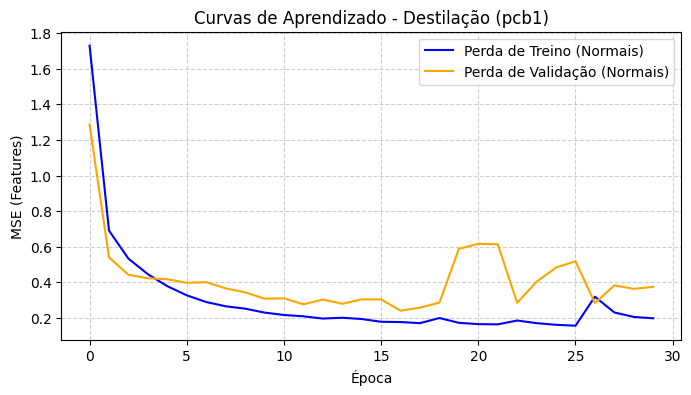


Treino finalizado! O melhor modelo foi salvo no disco.


In [10]:
import torch.optim as optim
from torch.nn import MSELoss
import matplotlib.pyplot as plt

# 1. Função de Perda e Otimizador
criterio = MSELoss()
otimizador = optim.Adam(aluna.parameters(), lr=1e-3, weight_decay=1e-5)

num_epocas = 30 # 30 épocas são suficientes para validar o fluxo inicial
melhor_perda_val = float('inf')
historico_treino = []
historico_val = []

print(f"Iniciando o treino em pcb1 por {num_epocas} épocas...")

for epoca in range(num_epocas):
    # --- LOOP DE TREINO ---
    aluna.train()
    perda_treino_epoca = 0.0

    for batch in dl_treino:
        imagens = batch["image"].to(DEV)
        otimizador.zero_grad()

        # 2. Precisão mista (dica prática do TP para acelerar na GPU)
        with torch.autocast(device_type=DEV if DEV == "cuda" else "cpu"):
            with torch.no_grad():
                f_prof1, f_prof2, f_prof3 = professora(imagens)

            f_alu1, f_alu2, f_alu3 = aluna(imagens)

            # A perda é a soma do erro de reconstrução das features nas 3 escalas
            perda = (criterio(f_alu1, f_prof1) +
                     criterio(f_alu2, f_prof2) +
                     criterio(f_alu3, f_prof3))

        perda.backward()
        otimizador.step()

        perda_treino_epoca += perda.item()

    perda_treino_epoca /= len(dl_treino)
    historico_treino.append(perda_treino_epoca)

    # --- LOOP DE VALIDAÇÃO ---
    # Usado APENAS para seleção de modelo, sem vazar imagens de teste
    aluna.eval()
    perda_val_epoca = 0.0

    with torch.no_grad():
        for batch in dl_val:
            imagens = batch["image"].to(DEV)

            with torch.autocast(device_type=DEV if DEV == "cuda" else "cpu"):
                f_prof1, f_prof2, f_prof3 = professora(imagens)
                f_alu1, f_alu2, f_alu3 = aluna(imagens)

                perda = (criterio(f_alu1, f_prof1) +
                         criterio(f_alu2, f_prof2) +
                         criterio(f_alu3, f_prof3))

            perda_val_epoca += perda.item()

    perda_val_epoca /= len(dl_val)
    historico_val.append(perda_val_epoca)

    # 3 e 4. Escolher a melhor época e salvar o checkpoint
    if perda_val_epoca < melhor_perda_val:
        melhor_perda_val = perda_val_epoca
        torch.save(aluna.state_dict(), "melhor_aluna_pcb1.pth")
        marcador = " [SALVO]"
    else:
        marcador = ""

    # Imprime a cada 5 épocas (e na primeira) para acompanhar
    if (epoca+1) % 5 == 0 or epoca == 0:
        print(f"Época [{epoca+1:02d}/{num_epocas}] | Treino: {perda_treino_epoca:.4f} | Val: {perda_val_epoca:.4f}{marcador}")

# 5. Plotar as curvas (obrigatório para o relatório da entrega)
plt.figure(figsize=(8, 4))
plt.plot(historico_treino, label="Perda de Treino (Normais)", color="blue")
plt.plot(historico_val, label="Perda de Validação (Normais)", color="orange")
plt.title("Curvas de Aprendizado - Destilação (pcb1)")
plt.xlabel("Época")
plt.ylabel("MSE (Features)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

print("\nTreino finalizado! O melhor modelo foi salvo no disco.")

In [11]:
import torch.nn.functional as F
import numpy as np

# 1. Carregar os melhores pesos salvos no checkpoint
aluna.load_state_dict(torch.load("melhor_aluna_pcb1.pth"))

# Regra crucial: colocar ambas em modo de avaliação
aluna.eval()
professora.eval()

# 2. NORMALIZAÇÃO (Regra R1): Descobrir a escala de erro usando apenas o split de VALIDAÇÃO
max_escore_val = 0.0

print("Calculando fator de normalização no conjunto de validação...")
with torch.no_grad():
    for batch in dl_val:
        imagens = batch["image"].to(DEV)

        with torch.autocast(device_type=DEV if DEV == "cuda" else "cpu"):
            f_prof1, f_prof2, f_prof3 = professora(imagens)
            f_alu1, f_alu2, f_alu3 = aluna(imagens)

        # Diferença quadrática em cada camada, somada ao longo dos canais
        dist1 = ((f_prof1 - f_alu1)**2).sum(1, keepdim=True)
        dist2 = ((f_prof2 - f_alu2)**2).sum(1, keepdim=True)
        dist3 = ((f_prof3 - f_alu3)**2).sum(1, keepdim=True)

        # Redimensiona para o tamanho final da imagem (256x256)
        mapa1 = F.interpolate(dist1, size=(256, 256), mode='bilinear', align_corners=False)
        mapa2 = F.interpolate(dist2, size=(256, 256), mode='bilinear', align_corners=False)
        mapa3 = F.interpolate(dist3, size=(256, 256), mode='bilinear', align_corners=False)

        mapa_soma = mapa1 + mapa2 + mapa3

        # Pega o maior valor do mapa para cada imagem do batch
        escores = mapa_soma.flatten(1).amax(1)
        max_escore_val = max(max_escore_val, escores.max().item())

print(f"Maior escore normal visto: {max_escore_val:.4f}. Usando como denominador de normalização.\n")


# 3. INFERÊNCIA NO TESTE
print("Extraindo mapas e pontuando o conjunto de teste...")
ds_teste = U.AnomalyDataset(RAIZ, "visa", "pcb1", split="test", transform=transformacao)
dl_teste = DataLoader(ds_teste, batch_size=32, num_workers=WORKERS)

rotulos, escores_finais, mascaras, mapas_anomalia = [], [], [], []

with torch.no_grad():
    for batch in dl_teste:
        imagens = batch["image"].to(DEV)

        with torch.autocast(device_type=DEV if DEV == "cuda" else "cpu"):
            f_prof1, f_prof2, f_prof3 = professora(imagens)
            f_alu1, f_alu2, f_alu3 = aluna(imagens)

        dist1 = ((f_prof1 - f_alu1)**2).sum(1, keepdim=True)
        dist2 = ((f_prof2 - f_alu2)**2).sum(1, keepdim=True)
        dist3 = ((f_prof3 - f_alu3)**2).sum(1, keepdim=True)

        mapa1 = F.interpolate(dist1, size=(256, 256), mode='bilinear', align_corners=False)
        mapa2 = F.interpolate(dist2, size=(256, 256), mode='bilinear', align_corners=False)
        mapa3 = F.interpolate(dist3, size=(256, 256), mode='bilinear', align_corners=False)

        mapa_final = mapa1 + mapa2 + mapa3

        # A regra de pontuação: o máximo do mapa
        escore_img = mapa_final.flatten(1).amax(1)
        # Normalização com o fator descoberto na validação
        escore_img_norm = escore_img / max_escore_val

        # Armazena tudo (removendo dimensão do canal para os mapas -> (B, 256, 256))
        mapas_anomalia.append(mapa_final[:, 0].cpu().numpy())
        escores_finais.append(escore_img_norm.cpu().numpy())
        rotulos.append(batch["label"].numpy())
        mascaras.append(batch["mask"][:, 0].numpy().astype(np.uint8))

# 4. AVALIAÇÃO OFICIAL
res_destilacao = U.avaliar_categoria(
    np.concatenate(rotulos),
    np.concatenate(escores_finais),
    np.concatenate(mascaras),
    np.concatenate(mapas_anomalia)
)

print("--- Resultados Finais: Destilação em pcb1 ---")
print(f"AUROC de Imagem : {res_destilacao['img_auroc']:.1f}%")
print(f"AUROC de Pixel  : {res_destilacao['px_auroc']:.1f}%")
print(f"AU-PRO@30%      : {res_destilacao['au_pro']:.1f}%")

Calculando fator de normalização no conjunto de validação...
Maior escore normal visto: 169.8750. Usando como denominador de normalização.

Extraindo mapas e pontuando o conjunto de teste...
--- Resultados Finais: Destilação em pcb1 ---
AUROC de Imagem : 71.0%
AUROC de Pixel  : 93.5%
AU-PRO@30%      : 42.6%


In [12]:
import pandas as pd
import torch.nn.functional as F
import gc

resultados_aluna = {}
num_epocas = 20 # Ajustado para 20 épocas para rodar as 12 categorias em tempo hábil

print("Iniciando Treino e Avaliação nas 12 categorias do VisA...\n")

for cat in U.CATEGORIAS["visa"]:
    print(f"--- Processando Categoria: {cat} ---")

    # 1. Pipeline de Dados (Cache na RAM)
    ds_tr = CachedAnomalyDataset(RAIZ, "visa", cat, "train", transformacao)
    ds_vl = CachedAnomalyDataset(RAIZ, "visa", cat, "val", transformacao)
    ds_te = U.AnomalyDataset(RAIZ, "visa", cat, "test", transformacao) # Teste não precisa de cache, lido 1x

    dl_tr = DataLoader(ds_tr, batch_size=32, shuffle=True, num_workers=WORKERS, pin_memory=True)
    dl_vl = DataLoader(ds_vl, batch_size=32, shuffle=False, num_workers=WORKERS, pin_memory=True)
    dl_te = DataLoader(ds_te, batch_size=32, shuffle=False, num_workers=WORKERS)

    # 2. Reinicializar a Rede Aluna e o Otimizador para cada categoria
    aluna_cat = RedeAluna().to(DEV)
    otimizador = optim.Adam(aluna_cat.parameters(), lr=1e-3, weight_decay=1e-5)

    melhor_perda_val = float('inf')
    melhor_estado = None

    # 3. Treino e Seleção de Modelo (Regra R1)
    for epoca in range(num_epocas):
        aluna_cat.train()
        for batch in dl_tr:
            img = batch["image"].to(DEV)
            otimizador.zero_grad()
            with torch.autocast(device_type=DEV if DEV == "cuda" else "cpu"):
                with torch.no_grad(): f_p1, f_p2, f_p3 = professora(img)
                f_a1, f_a2, f_a3 = aluna_cat(img)
                perda = criterio(f_a1, f_p1) + criterio(f_a2, f_p2) + criterio(f_a3, f_p3)
            perda.backward()
            otimizador.step()

        # Validação
        aluna_cat.eval()
        perda_val = 0.0
        with torch.no_grad():
            for batch in dl_vl:
                img = batch["image"].to(DEV)
                with torch.autocast(device_type=DEV if DEV == "cuda" else "cpu"):
                    f_p1, f_p2, f_p3 = professora(img)
                    f_a1, f_a2, f_a3 = aluna_cat(img)
                    perda_val += (criterio(f_a1, f_p1) + criterio(f_a2, f_p2) + criterio(f_a3, f_p3)).item()

        perda_val /= len(dl_vl)
        if perda_val < melhor_perda_val:
            melhor_perda_val = perda_val
            melhor_estado = aluna_cat.state_dict().copy()

    # Carrega o melhor modelo da categoria
    aluna_cat.load_state_dict(melhor_estado)
    aluna_cat.eval()

    # 4. Normalização (Baseada na Validação)
    max_escore_val = 0.0
    with torch.no_grad():
        for batch in dl_vl:
            img = batch["image"].to(DEV)
            with torch.autocast(device_type=DEV if DEV == "cuda" else "cpu"):
                f_p1, f_p2, f_p3 = professora(img)
                f_a1, f_a2, f_a3 = aluna_cat(img)

            # Cálculo dos mapas e suavização espacial (AvgPool)
            dist1 = F.avg_pool2d(((f_p1 - f_a1)**2).sum(1, keepdim=True), kernel_size=5, stride=1, padding=2)
            dist2 = F.avg_pool2d(((f_p2 - f_a2)**2).sum(1, keepdim=True), kernel_size=5, stride=1, padding=2)
            dist3 = F.avg_pool2d(((f_p3 - f_a3)**2).sum(1, keepdim=True), kernel_size=5, stride=1, padding=2)

            m1 = F.interpolate(dist1, size=(256, 256), mode='bilinear', align_corners=False)
            m2 = F.interpolate(dist2, size=(256, 256), mode='bilinear', align_corners=False)
            m3 = F.interpolate(dist3, size=(256, 256), mode='bilinear', align_corners=False)

            escores = (m1 + m2 + m3).flatten(1).amax(1)
            max_escore_val = max(max_escore_val, escores.max().item())

    # 5. Avaliação Oficial no Teste (Regra R2)
    rotulos, esc_finais, mascaras, mapas_anom = [], [], [], []
    with torch.no_grad():
        for batch in dl_te:
            img = batch["image"].to(DEV)
            with torch.autocast(device_type=DEV if DEV == "cuda" else "cpu"):
                f_p1, f_p2, f_p3 = professora(img)
                f_a1, f_a2, f_a3 = aluna_cat(img)

            # Filtro de Suavização também aplicado na inferência
            dist1 = F.avg_pool2d(((f_p1 - f_a1)**2).sum(1, keepdim=True), kernel_size=5, stride=1, padding=2)
            dist2 = F.avg_pool2d(((f_p2 - f_a2)**2).sum(1, keepdim=True), kernel_size=5, stride=1, padding=2)
            dist3 = F.avg_pool2d(((f_p3 - f_a3)**2).sum(1, keepdim=True), kernel_size=5, stride=1, padding=2)

            m1 = F.interpolate(dist1, size=(256, 256), mode='bilinear', align_corners=False)
            m2 = F.interpolate(dist2, size=(256, 256), mode='bilinear', align_corners=False)
            m3 = F.interpolate(dist3, size=(256, 256), mode='bilinear', align_corners=False)

            m_final = m1 + m2 + m3
            esc_img = m_final.flatten(1).amax(1) / (max_escore_val + 1e-8)

            mapas_anom.append(m_final[:, 0].cpu().numpy())
            esc_finais.append(esc_img.cpu().numpy())
            rotulos.append(batch["label"].numpy())
            mascaras.append(batch["mask"][:, 0].numpy().astype(np.uint8))

    res = U.avaliar_categoria(
        np.concatenate(rotulos), np.concatenate(esc_finais),
        np.concatenate(mascaras), np.concatenate(mapas_anom)
    )
    resultados_aluna[cat] = res
    print(f"-> img_auroc: {res['img_auroc']:.1f}% | px_auroc: {res['px_auroc']:.1f}% | au_pro: {res['au_pro']:.1f}%\n")

    # Limpeza de memória
    del aluna_cat, otimizador, ds_tr, ds_vl, ds_te, dl_tr, dl_vl, dl_te
    gc.collect()
    torch.cuda.empty_cache()

# 6. Geração da Tabela e Cálculo do S_grad
tabela_aluna = U.avaliar_dataset(resultados_aluna, "visa")
tabela_aluna.rename(columns={"img_auroc": "img_auroc_aluna", "px_auroc": "px_auroc_aluna", "au_pro": "au_pro_aluna"}, inplace=True)

U.salvar_submissao([tabela_aluna], "submissao-destilacao.csv")

# 7. Comparação Obrigatória com o Baseline (Fundindo as tabelas)
tabela_baseline = pd.read_csv("baseline-resnet18.csv")
comparativo = pd.merge(tabela_aluna, tabela_baseline, on=["dataset", "categoria"])

print("\n=== COMPARAÇÃO FINAL: ALUNA vs BASELINE ===")
print(comparativo[["categoria", "img_auroc_aluna", "img_auroc", "au_pro_aluna", "au_pro"]])

s_grad = comparativo[comparativo["categoria"] == "MEDIA"]["img_auroc_aluna"].values[0]
print(f"\n🎉 SEU ESCORE DA COMPETIÇÃO (S_grad): {s_grad:.2f}% 🎉")

Iniciando Treino e Avaliação nas 12 categorias do VisA...

--- Processando Categoria: candle ---
Pré-carregando 810 imagens do split 'train' na memória...


100%|██████████| 810/810 [00:13<00:00, 58.36it/s]


Pré-carregando 90 imagens do split 'val' na memória...


100%|██████████| 90/90 [00:01<00:00, 56.56it/s]


-> img_auroc: 52.2% | px_auroc: 87.1% | au_pro: 71.1%

--- Processando Categoria: capsules ---
Pré-carregando 488 imagens do split 'train' na memória...


...

-> img_auroc: 36.5% | px_auroc: 46.8% | au_pro: 7.5%

--- Processando Categoria: pipe_fryum ---
Pré-carregando 405 imagens do split 'train' na memória...


100%|██████████| 405/405 [00:06<00:00, 59.16it/s]


Pré-carregando 45 imagens do split 'val' na memória...


100%|██████████| 45/45 [00:00<00:00, 62.86it/s]


-> img_auroc: 57.9% | px_auroc: 97.4% | au_pro: 85.4%

dataset categoria  img_auroc_aluna  px_auroc_aluna  au_pro_aluna
   visa     MEDIA            62.92           87.27         60.97

=== COMPARAÇÃO FINAL: ALUNA vs BASELINE ===
     categoria  img_auroc_aluna  img_auroc  au_pro_aluna  au_pro
0       candle        52.165000      85.92     71.100587   91.41
1     capsules        69.900000      55.63     66.470589   44.15
2       cashew        83.930000      73.34     88.926352   78.87
3   chewinggum        49.500000      94.06     69.906606   76.33
4        fryum        77.480000      80.18     77.102313   75.00
5    macaroni1        81.910000      75.09     38.600116   78.69
6    macaroni2        53.785000      54.62     77.142811   74.34
7         pcb1        73.995000      83.93     29.430945   59.97
8         pcb2        70.000000      76.19     67.264861   73.52
9         pcb3        48.024752      68.22     52.889295   72.36
10        pcb4        36.500000      93.20      7.49455

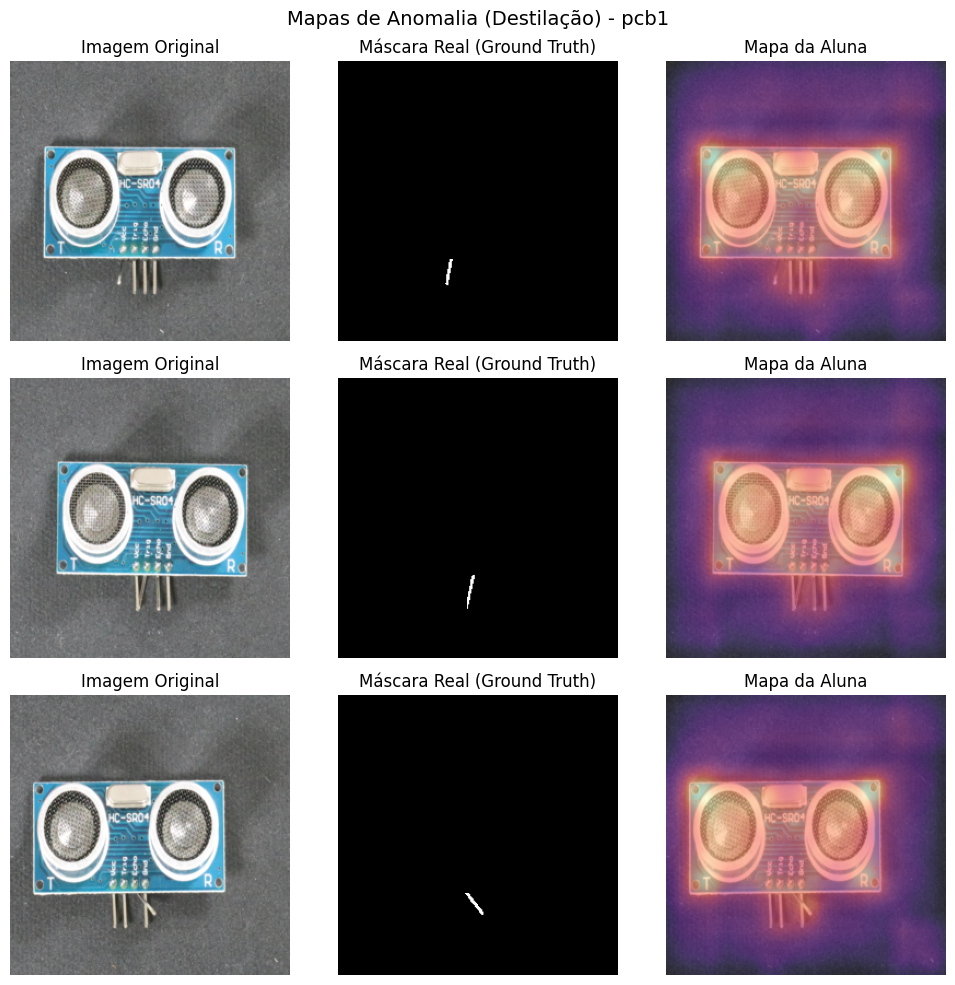

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import torch.nn.functional as F

# 1. Carregar o modelo para uma categoria específica (ex: pcb1)
categoria_plot = "pcb1"
aluna.load_state_dict(torch.load(f"melhor_aluna_{categoria_plot}.pth"))
aluna.eval()
professora.eval()

# 2. Pegar algumas imagens anômalas do teste
ds_teste_plot = U.AnomalyDataset(RAIZ, "visa", categoria_plot, split="test", transform=transformacao)
anomalas_idx = [i for i, item in enumerate(ds_teste_plot) if item["label"] == 1]

# Selecionar 3 exemplos para a figura
exemplos = anomalas_idx[:3]

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
fig.suptitle(f"Mapas de Anomalia (Destilação) - {categoria_plot}", fontsize=14)

with torch.no_grad():
    for row, idx in enumerate(exemplos):
        item = ds_teste_plot[idx]
        img_tensor = item["image"].unsqueeze(0).to(DEV)
        mascara_real = item["mask"][0].numpy()
        img_rgb = U.desnormalizar(item["image"]) # Imagem original para o plot

        # Inferência
        with torch.autocast(device_type=DEV if DEV == "cuda" else "cpu"):
            f_p1, f_p2, f_p3 = professora(img_tensor)
            f_a1, f_a2, f_a3 = aluna(img_tensor)

        # Calcula a diferença com suavização
        dist1 = F.avg_pool2d(((f_p1 - f_a1)**2).sum(1, keepdim=True), kernel_size=5, stride=1, padding=2)
        dist2 = F.avg_pool2d(((f_p2 - f_a2)**2).sum(1, keepdim=True), kernel_size=5, stride=1, padding=2)
        dist3 = F.avg_pool2d(((f_p3 - f_a3)**2).sum(1, keepdim=True), kernel_size=5, stride=1, padding=2)

        m1 = F.interpolate(dist1, size=(256, 256), mode='bilinear', align_corners=False)
        m2 = F.interpolate(dist2, size=(256, 256), mode='bilinear', align_corners=False)
        m3 = F.interpolate(dist3, size=(256, 256), mode='bilinear', align_corners=False)

        mapa_final = (m1 + m2 + m3)[0, 0].cpu().numpy()

        # Plot 1: Imagem Original
        axes[row, 0].imshow(img_rgb)
        axes[row, 0].set_title("Imagem Original")
        axes[row, 0].axis("off")

        # Plot 2: Máscara Real
        axes[row, 1].imshow(mascara_real, cmap="gray")
        axes[row, 1].set_title("Máscara Real (Ground Truth)")
        axes[row, 1].axis("off")

        # Plot 3: Mapa de Anomalia sobreposto
        axes[row, 2].imshow(img_rgb)
        # O cmap "magma" ou "inferno" com alpha destaca bem as regiões de anomalia
        axes[row, 2].imshow(mapa_final, cmap="magma", alpha=0.6)
        axes[row, 2].set_title("Mapa da Aluna")
        axes[row, 2].axis("off")

plt.tight_layout()
plt.show()